# UAS Data Mining — Random Forest Classification
**Dataset:** Crop Irrigation Prediction (`datasetcropclean.csv`)  
**Target:** `result` — 0 = Irrigation Not Required | 1 = Irrigation Required | 2 = Class 2  
**Model:** Random Forest Classifier (Multiclass)

---

## 1. Import Libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay
)

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='Set2')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11

print(' Libraries imported successfully.')

 Libraries imported successfully.


## 2. Load the Prepared Dataset

In [ ]:
url = f"https://drive.google.com/uc?id=1sScVxMr5uk2DfmK7rA3z13O1-_oEL6p-"

df = pd.read_csv(url)

print(f' Dataset loaded successfully.')
print(f'   Number of rows   : {df.shape[0]:,}')
print(f'   Number of columns   : {df.shape[1]}')
print(f'\n   Dataset columns:')
for col in df.columns:
    print(f'   - {col} ({df[col].dtype})')

 Dataset loaded successfully.
   Number of rows   : 16,283
   Number of columns   : 17

   Dataset columns:
   - Seedling Stage (int64)
   - MOI (int64)
   - temp (int64)
   - humidity (float64)
   - result (int64)
   - crop ID_Carrot (bool)
   - crop ID_Chilli (bool)
   - crop ID_Potato (bool)
   - crop ID_Tomato (bool)
   - crop ID_Wheat (bool)
   - soil_type_Alluvial Soil (bool)
   - soil_type_Black Soil (bool)
   - soil_type_Chalky Soil (bool)
   - soil_type_Clay Soil (bool)
   - soil_type_Loam Soil (bool)
   - soil_type_Red Soil (bool)
   - soil_type_Sandy Soil (bool)


In [ ]:
df.head(10)

,Seedling Stage,MOI,temp,humidity,result,crop ID_Carrot,crop ID_Chilli,crop ID_Potato,crop ID_Tomato,crop ID_Wheat,soil_type_Alluvial Soil,soil_type_Black Soil,soil_type_Chalky Soil,soil_type_Clay Soil,soil_type_Loam Soil,soil_type_Red Soil,soil_type_Sandy Soil
0,2,1,25,80.0,1,False,False,False,False,True,False,True,False,False,False,False,False
1,2,2,26,77.0,1,False,False,False,False,True,False,True,False,False,False,False,False
2,2,3,27,74.0,1,False,False,False,False,True,False,True,False,False,False,False,False
3,2,4,28,71.0,1,False,False,False,False,True,False,True,False,False,False,False,False
4,2,5,29,68.0,1,False,False,False,False,True,False,True,False,False,False,False,False
5,2,6,30,65.0,1,False,False,False,False,True,False,True,False,False,False,False,False
6,2,7,31,62.0,1,False,False,False,False,True,False,True,False,False,False,False,False
7,2,8,32,59.0,1,False,False,False,False,True,False,True,False,False,False,False,False
8,2,9,33,56.0,1,False,False,False,False,True,False,True,False,False,False,False,False
9,2,10,34,53.0,1,False,False,False,False,True,False,True,False,False,False,False,False


## 3. Separate Features (X) and Target (y)

In [ ]:
TARGET = 'result'

X = df.drop(columns=[TARGET])
y = df[TARGET]

print(f' Features and target separated successfully.')
print(f'   Shape X (features) : {X.shape}')
print(f'   Shape y (target): {y.shape}')
print(f'\n   Target class distribution:')
for class_id, count in y.value_counts().sort_index().items():
    print(f'   Class {kelas} : {count:,} samples ({jumlah/len(y)*100:.2f}%)')

 Features and target separated successfully.
   Shape X (features) : (16283, 16)
   Shape y (target): (16283,)

   Target class distribution:
   Class 0 : 8,934 samples (54.87%)
   Class 1 : 6,227 samples (38.24%)
   Class 2 : 1,122 samples (6.89%)


## 4. Stratified Train-Validation-Test Split
> Proportions: **Train 70%** | **Validation 15%** | **Test 15%**  
> Stratified splitting keeps class proportions consistent across each subset.

In [ ]:
# Step 1: Split into Train (70%) and Temporary (30%)
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# Step 2: Split Temporary into Validation (15%) and Test (15%)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print(' Stratified train-validation-test split completed.')
print(f'   Training set  : {X_train.shape[0]:,} samples ({X_train.shape[0]/len(X)*100:.1f}%)')
print(f'   Validation set: {X_val.shape[0]:,} samples ({X_val.shape[0]/len(X)*100:.1f}%)')
print(f'   Test set      : {X_test.shape[0]:,} samples ({X_test.shape[0]/len(X)*100:.1f}%)')

print('\n   Verify class proportions (stratified):')
for nama, y_split in [('Train', y_train), ('Val', y_val), ('Test', y_test)]:
    props = y_split.value_counts(normalize=True).sort_index()
    prop_str = ' | '.join([f'Class {k}: {v*100:.1f}%' for k, v in props.items()])
    print(f'   {nama:5s}: {prop_str}')

 Stratified train-validation-test split completed.
   Training set  : 11,398 samples (70.0%)
   Validation set: 2,442 samples (15.0%)
   Test set      : 2,443 samples (15.0%)

   Verify class proportions (stratified):
   Train: Class 0: 54.9% | Class 1: 38.2% | Class 2: 6.9%
   Val  : Class 0: 54.9% | Class 1: 38.2% | Class 2: 6.9%
   Test : Class 0: 54.9% | Class 1: 38.2% | Class 2: 6.9%


## 5. Train the Random Forest Baseline
> The initial model uses default parameters as a benchmark before hyperparameter tuning.

In [ ]:
print(' Training the Random Forest baseline model...')
# Use default parameters
# n_estimators = 100
# max_depth = None

rf_baseline = RandomForestClassifier(
    class_weight='balanced',
    random_state=42
)
rf_baseline.fit(X_train, y_train) # training

y_pred_baseline = rf_baseline.predict(X_val) # prediction
acc_baseline = accuracy_score(y_val, y_pred_baseline)
f1_baseline  = f1_score(y_val, y_pred_baseline, average='macro')

print(f'\n Baseline model training completed.')
print(f'   Accuracy (Val) : {acc_baseline:.4f} ({acc_baseline*100:.2f}%)')
print(f'   F1-Macro (Val) : {f1_baseline:.4f}')
print('\n   \U0001f4cc Baseline Interpretation:')
print(f'   The baseline model (without tuning) achieved an accuracy of {acc_baseline*100:.2f}%')
print('   on the validation set. This serves as the initial benchmark before hyperparameter tuning.')

⏳ Training the Random Forest baseline model...

 Baseline model training completed.
   Accuracy (Val) : 0.9836 (98.36%)
   F1-Macro (Val) : 0.9523

    Baseline Interpretation:
   The baseline model (without tuning) achieved an accuracy of 98.36%
   on the validation set. This serves as the initial benchmark before hyperparameter tuning.


## 6. Hyperparameter Tuning — GridSearchCV
> The parameter grid is limited to keep the process reasonably fast in Colab.  
> **F1-Macro** is used for scoring so that all classes receive equal weight.

In [ ]:
print(' Running GridSearchCV (may take a few minutes)...')

param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [10, 20, None]
}

grid_search = GridSearchCV(
    RandomForestClassifier(
        class_weight='balanced',
        random_state=42
    ),
    param_grid=param_grid,
    cv=3,
    scoring='f1_macro',
    n_jobs=-1,
    verbose=1
)

# Fit only on the training set to avoid data leakage
grid_search.fit(X_train, y_train)

print(f'\n GridSearchCV completed.')
print(f'   Best parameters  : {grid_search.best_params_}')
print(f'   Best CV F1-Macro: {grid_search.best_score_:.4f}')

print('\n   \U0001f4ca Summary of all parameter combinations:')
cv_results = pd.DataFrame(grid_search.cv_results_)
cols_show  = ['param_n_estimators', 'param_max_depth',
              'mean_test_score', 'std_test_score', 'rank_test_score']
cv_summary = cv_results[cols_show].sort_values('rank_test_score')
cv_summary.columns = ['n_estimators', 'max_depth', 'F1-Macro (CV)', 'Std', 'Rank']
cv_summary['F1-Macro (CV)'] = cv_summary['F1-Macro (CV)'].round(4)
cv_summary['Std'] = cv_summary['Std'].round(4)
display(cv_summary.reset_index(drop=True))

⏳ Running GridSearchCV (may take a few minutes)...
Fitting 3 folds for each of 6 candidates, totalling 18 fits

 GridSearchCV completed.
   Best parameters  : {'max_depth': 20, 'n_estimators': 200}
   Best CV F1-Macro: 0.9066

    Summary of all parameter combinations:


,n_estimators,max_depth,F1-Macro (CV),Std,Rank
0,200,20,0.9066,0.0049,1
1,100,20,0.9032,0.0029,2
2,200,None,0.9011,0.0047,3
3,100,None,0.8989,0.0022,4
4,200,10,0.8186,0.0069,5
5,100,10,0.8170,0.0076,6


## 7. Evaluate the Best Model on the Validation Set
> Evaluation uses Accuracy, Precision, Recall, F1-Score (Macro), and the Classification Report.

In [ ]:
print('=' * 60)
print('  BEST MODEL EVALUATION — VALIDATION SET')
print('=' * 60)

best_model = grid_search.best_estimator_
y_pred_val = best_model.predict(X_val)

acc_val  = accuracy_score(y_val, y_pred_val)
prec_val = precision_score(y_val, y_pred_val, average='macro')
rec_val  = recall_score(y_val, y_pred_val, average='macro')
f1_val   = f1_score(y_val, y_pred_val, average='macro')

print(f'\n  Accuracy  : {acc_val:.4f} ({acc_val*100:.4f}%)')
print(f'  Precision : {prec_val:.4f} (Macro)')
print(f'  Recall    : {rec_val:.4f} (Macro)')
print(f'  F1-Score  : {f1_val:.4f} (Macro)')
print('\n  Classification Report (Validation Set):')
print(classification_report(y_val, y_pred_val,
                             target_names=['Class 0', 'Class 1', 'Class 2']))
print('\n  \U0001f4cc Validation Set Interpretation:')
print(f'  - Accuracy {acc_val*100:.4f}% means the model correctly predicts {acc_val*100:.4f}% of all validation data.')
print(f'  - F1-Macro {f1_val:.4f} measures the average F1 score across all three classes equally,')
print('    so performance on the minority class (Class 2) is also considered.')
print('  - Class 2 usually has a lower F1-Score because it has the fewest samples (~7%).')

  BEST MODEL EVALUATION — VALIDATION SET

  Accuracy  : 0.9840 (98.4029%)
  Precision : 0.9824 (Macro)
  Recall    : 0.9312 (Macro)
  F1-Score  : 0.9537 (Macro)

  Classification Report (Validation Set):
              precision    recall  f1-score   support

     Class 0       0.98      1.00      0.99      1340
     Class 1       0.99      1.00      0.99       934
     Class 2       0.98      0.80      0.88       168

    accuracy                           0.98      2442
   macro avg       0.98      0.93      0.95      2442
weighted avg       0.98      0.98      0.98      2442


   Validation Set Interpretation:
  - Accuracy 98.4029% means the model correctly predicts 98.4029% of all validation data.
  - F1-Macro 0.9537 measures the average F1 score across all three classes equally,
    so performance on the minority class (Class 2) is also considered.
  - Class 2 usually has a lower F1-Score because it has the fewest samples (~7%).


## 8. Retrain the Best Model on the Train + Validation Sets
> After finding the best parameters, the training and validation sets are combined and the model is retrained.  
> This allows the model to use as much data as possible before the final evaluation on the test set.

In [ ]:
print(' Combining the Train + Validation sets and retraining the best model...')

X_trainval = pd.concat([X_train, X_val], axis=0)
y_trainval = pd.concat([y_train, y_val], axis=0)

print(f'   Train+Val size : {X_trainval.shape[0]:,} data')

best_params = grid_search.best_params_

rf_final = RandomForestClassifier(
    n_estimators=best_params['n_estimators'],
    max_depth=best_params['max_depth'],
    class_weight='balanced',
    random_state=42
)
rf_final.fit(X_trainval, y_trainval)

print(' Final model successfully trained on the Train+Val set.')

⏳ Combining the Train + Validation sets and retraining the best model...
   Train+Val size : 13,840 data
 Final model successfully trained on the Train+Val set.


## 9. Evaluate the Final Model on the Test Set
> The test set has **never been seen by the model** — this provides an estimate of its real-world performance.

In [ ]:
print('=' * 60)
print('  FINAL MODEL EVALUATION — TEST SET')
print('=' * 60)

y_pred_test = rf_final.predict(X_test)

acc_test  = accuracy_score(y_test, y_pred_test)
prec_test = precision_score(y_test, y_pred_test, average='macro')
rec_test  = recall_score(y_test, y_pred_test, average='macro')
f1_test   = f1_score(y_test, y_pred_test, average='macro')

print(f'\n  Accuracy  : {acc_test:.4f} ({acc_test*100:.2f}%)')
print(f'  Precision : {prec_test:.4f} (Macro)')
print(f'  Recall    : {rec_test:.4f} (Macro)')
print(f'  F1-Score  : {f1_test:.4f} (Macro)')
print('\n  Classification Report (Test Set):')
print(classification_report(y_test, y_pred_test,digits=4,
                             target_names=['Class 0', 'Class 1', 'Class 2']))
print('\n  \U0001f4cc Test Set Interpretation:')
print('  - The test set is data the model has never seen before.')
print(f'  - Accuracy {acc_test*100:.2f}% represents the model's real-world performance.')
print(f'  - Compare with the validation result ({acc_val*100:.2f}%) to detect overfitting.')

  FINAL MODEL EVALUATION — TEST SET

  Accuracy  : 0.9844 (98.44%)
  Precision : 0.9798 (Macro)
  Recall    : 0.9351 (Macro)
  F1-Score  : 0.9550 (Macro)

  Classification Report (Test Set):
              precision    recall  f1-score   support

     Class 0     0.9918    0.9978    0.9948      1340
     Class 1     0.9759    0.9968    0.9862       934
     Class 2     0.9716    0.8107    0.8839       169

    accuracy                         0.9844      2443
   macro avg     0.9798    0.9351    0.9550      2443
weighted avg     0.9843    0.9844    0.9838      2443


   Test Set Interpretation:
  - The test set is data the model has never seen before.
  - Accuracy 98.44% represents the model's real-world performance.
  - Compare with the validation result (98.40%) to detect overfitting.


## 10. Confusion Matrix
> **Main diagonal** = correct predictions | **Off-diagonal values** = misclassifications.

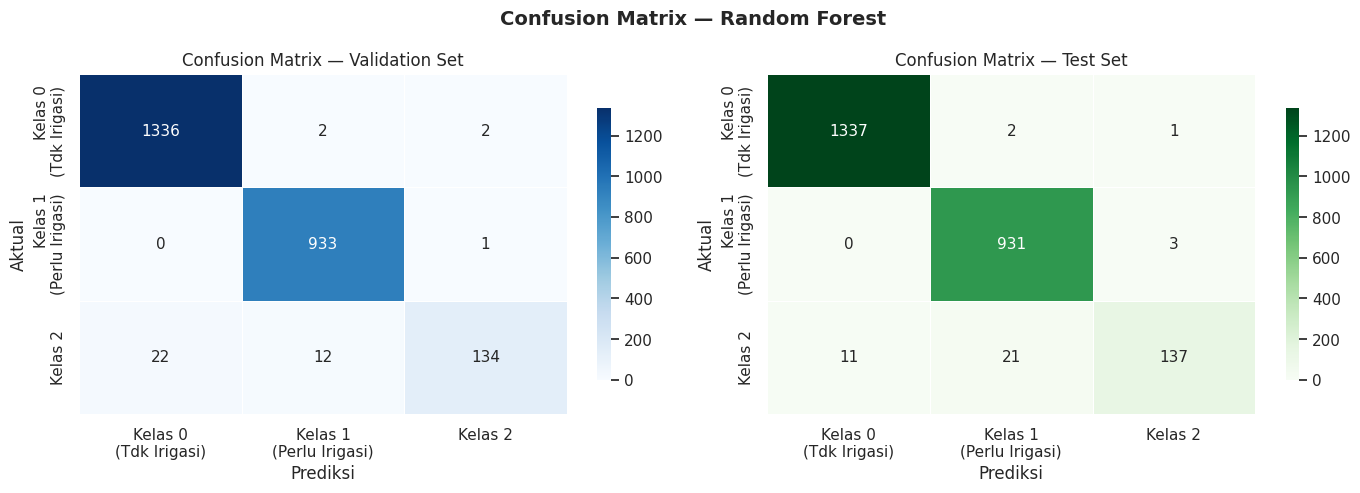


   How to read the Confusion Matrix:
  - Main diagonal (top-left to bottom-right) = CORRECT predictions.
  - Off-diagonal = INCORRECT predictions (misclassifications).
  - Check the Class 2 row: if many are misclassified as Class 0/1,
    this may be due to class imbalance even when using class_weight="balanced".


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Confusion Matrix — Random Forest', fontsize=14, fontweight='bold')

class_label = ['Class 0\n(No Irrigation)', 'Class 1\n(Irrigation Required)', 'Class 2']

# Validation Set
cm_val = confusion_matrix(y_val, y_pred_val)
sns.heatmap(cm_val, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_label, yticklabels=class_label, ax=axes[0],
            linewidths=0.5, cbar_kws={'shrink': 0.8})
axes[0].set_title('Confusion Matrix — Validation Set')
axes[0].set_xlabel('Prediction')
axes[0].set_ylabel('Actual')

# Test Set
cm_test = confusion_matrix(y_test, y_pred_test)
sns.heatmap(cm_test, annot=True, fmt='d', cmap='Greens',
            xticklabels=class_label, yticklabels=class_label, ax=axes[1],
            linewidths=0.5, cbar_kws={'shrink': 0.8})
axes[1].set_title('Confusion Matrix — Test Set')
axes[1].set_xlabel('Prediction')
axes[1].set_ylabel('Actual')

plt.tight_layout()
plt.show()

print('\n  \U0001f4cc How to read the Confusion Matrix:')
print('  - Main diagonal (top-left to bottom-right) = CORRECT predictions.')
print('  - Off-diagonal = INCORRECT predictions (misclassifications).')
print('  - Check the Class 2 row: if many are misclassified as Class 0/1,')
print('    this may be due to class imbalance even when using class_weight="balanced".')

## 11. Overfitting Analysis
> Compare **Training** and **Test** performance.  
> Difference < 5% = acceptable | 5–10% = mild | > 10% = significant.

  OVERFITTING ANALYSIS

  Training (Train+Val) vs Test Performance:
  Metric              Training         Test      Difference
  ---------------------------------------------------
  Accuracy              1.0000       0.9844       0.0156
  F1-Macro              1.0000       0.9550       0.0450


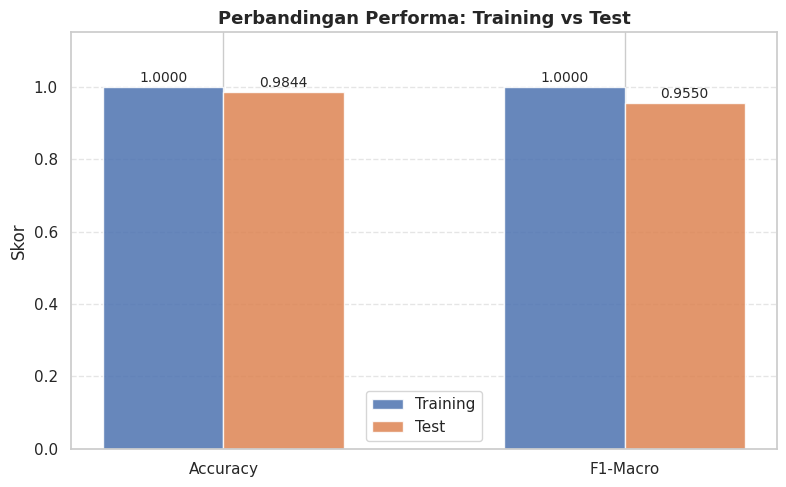


   Overfitting Interpretation:
   The model does NOT show significant overfitting.
     Difference Accuracy: 0.0156 | Difference F1-Macro: 0.0450
     Training and test performance are relatively balanced.


In [ ]:
print('=' * 60)
print('  OVERFITTING ANALYSIS')
print('=' * 60)

y_pred_train = rf_final.predict(X_trainval)
acc_train = accuracy_score(y_trainval, y_pred_train)
f1_train  = f1_score(y_trainval, y_pred_train, average='macro')

selisih_acc = abs(acc_train - acc_test)
selisih_f1  = abs(f1_train  - f1_test)

print(f'\n  Training (Train+Val) vs Test Performance:')
print(f'  {"Metric":<15} {"Training":>12} {"Test":>12} {"Difference":>12}')
print(f'  {"-"*51}')
print(f'  {"Accuracy":<15} {acc_train:>12.4f} {acc_test:>12.4f} {selisih_acc:>12.4f}')
print(f'  {"F1-Macro":<15} {f1_train:>12.4f} {f1_test:>12.4f} {selisih_f1:>12.4f}')

# Visualization
metrics_names = ['Accuracy', 'F1-Macro']
train_scores  = [acc_train, f1_train]
test_scores   = [acc_test, f1_test]

x = np.arange(len(metrics_names))
width = 0.30

fig, ax = plt.subplots(figsize=(8, 5))
bars1 = ax.bar(x - width/2, train_scores, width, label='Training', color='#4C72B0', alpha=0.85)
bars2 = ax.bar(x + width/2, test_scores,  width, label='Test',     color='#DD8452', alpha=0.85)

for bar in bars1:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
            f'{bar.get_height():.4f}', ha='center', va='bottom', fontsize=10)
for bar in bars2:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
            f'{bar.get_height():.4f}', ha='center', va='bottom', fontsize=10)

ax.set_title('Performance Comparison: Training vs Test', fontsize=13, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(metrics_names)
ax.set_ylim(0, 1.15)
ax.set_ylabel('Score')
ax.legend()
ax.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

print('\n  \U0001f4cc Overfitting Interpretation:')
if selisih_acc < 0.05 and selisih_f1 < 0.05:
    print('   The model does NOT show significant overfitting.')
    print(f'     Difference Accuracy: {selisih_acc:.4f} | Difference F1-Macro: {selisih_f1:.4f}')
    print('     Training and test performance are relatively balanced.')
elif selisih_acc < 0.10:
    print('    The model shows MILD overfitting.')
    print(f'     Difference Accuracy: {selisih_acc:.4f} | Difference F1-Macro: {selisih_f1:.4f}')
    print('     Consider reducing max_depth or increasing min_samples_split.')
else:
    print('   The model shows SIGNIFICANT overfitting.')
    print(f'     Difference Accuracy: {selisih_acc:.4f} | Difference F1-Macro: {selisih_f1:.4f}')
    print('     Further regularization is required (reduce max_depth, increase min_samples_leaf).')

## 12. Feature Importance
> Shows how much each feature contributes to the model's decisions.

  Feature Importance Table (descending order):


,Feature,Importance,Importance (%)
1,MOI,0.427879,42.79
2,temp,0.223600,22.36
3,humidity,0.186396,18.64
4,Seedling Stage,0.097863,9.79
5,crop ID_Wheat,0.011410,1.14
6,soil_type_Clay Soil,0.006955,0.70
7,crop ID_Chilli,0.006862,0.69
8,crop ID_Potato,0.006853,0.69
9,soil_type_Loam Soil,0.005902,0.59
10,soil_type_Sandy Soil,0.005421,0.54


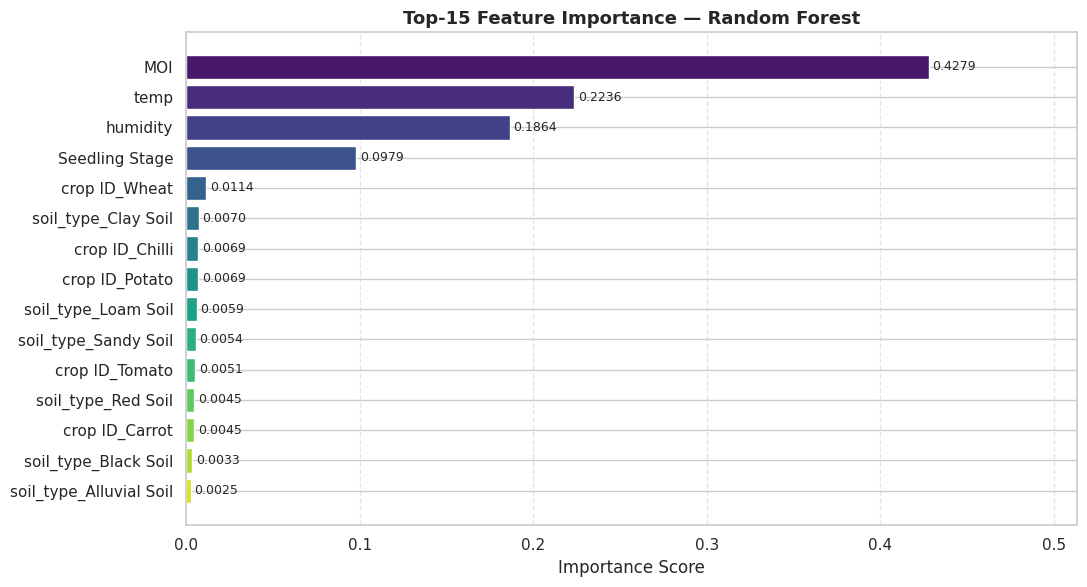


   Feature Importance Interpretation:
  - "MOI" (42.79%) => the most influential feature for prediction.
  - "temp" (22.36%) => the most influential feature for prediction.
  - "humidity" (18.64%) => the most influential feature for prediction.
  - A feature with high importance means the model often selects it
    as a split point in a decision tree.
  - Features with importance close to 0 may be considered for removal.


In [ ]:
importances   = rf_final.feature_importances_
feature_names = X.columns.tolist()

fi_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values('Importance', ascending=False).reset_index(drop=True)
fi_df['Importance (%)'] = (fi_df['Importance'] * 100).round(2)
fi_df.index = fi_df.index + 1

print('  Feature Importance Table (descending order):')
display(fi_df[['Feature', 'Importance', 'Importance (%)']])

# Plot
top_n  = min(15, len(fi_df))
fi_top = fi_df.head(top_n)

palette = sns.color_palette('viridis', top_n)
fig, ax = plt.subplots(figsize=(11, 6))
bars = ax.barh(fi_top['Feature'][::-1], fi_top['Importance'][::-1],
               color=palette[::-1], edgecolor='white')
for bar, val in zip(bars, fi_top['Importance'][::-1]):
    ax.text(bar.get_width() + 0.002, bar.get_y() + bar.get_height()/2,
            f'{val:.4f}', va='center', fontsize=9)
ax.set_title(f'Top-{top_n} Feature Importance — Random Forest', fontsize=13, fontweight='bold')
ax.set_xlabel('Importance Score')
ax.set_xlim(0, fi_top['Importance'].max() * 1.20)
ax.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

print('\n  \U0001f4cc Feature Importance Interpretation:')
top3 = fi_df.head(3)
for _, row in top3.iterrows():
    print(f'  - "{row["Feature"]}" ({row["Importance (%)"]:.2f}%) => the most influential feature for prediction.')
print('  - A feature with high importance means the model often selects it')
print('    as a split point in a decision tree.')
print('  - Features with importance close to 0 may be considered for removal.')

## 13. Sample Predictions from the Test Set
> Selects **5 random samples from the test set** (not the entire dataset) to avoid data leakage.

In [ ]:
np.random.seed(42)
sample_idx    = np.random.choice(len(X_test), size=5, replace=False)

X_sample      = X_test.iloc[sample_idx].reset_index(drop=True)
y_true_sample = y_test.iloc[sample_idx].reset_index(drop=True)

y_pred_sample = rf_final.predict(X_sample)

label_map = {0: 'Irrigation Not Required', 1: 'Irrigation Required', 2: 'Class 2'}

print('  Sample data from the test set:')
display(X_sample[['Seedling Stage', 'MOI', 'temp', 'humidity']])

print('\n  Prediction results:')
print(f'  {"No":<5} {"Actual Label":<25} {"Predicted Label":<25} {"Status"}')
print(f'  {"-"*70}')
for i in range(len(X_sample)):
    aktual   = label_map[y_true_sample.iloc[i]]
    prediksi = label_map[y_pred_sample[i]]
    status   = ' Correct' if y_true_sample.iloc[i] == y_pred_sample[i] else ' Incorrect'
    print(f'  {i+1:<5} {aktual:<25} {prediksi:<25} {status}')

  Sample data from the test set:


,Seedling Stage,MOI,temp,humidity
0,0,80,40,35.0
1,5,37,37,44.0
2,2,5,29,68.0
3,6,83,25,80.0
4,6,9,31,60.0



  Prediction results:
  No    Actual Label              Predicted Label            Status
  ----------------------------------------------------------------------
  1     Irrigation Not Required       Irrigation Not Required        Correct
  2     Irrigation Required             Irrigation Required              Correct
  3     Irrigation Required             Irrigation Required              Correct
  4     Irrigation Not Required       Irrigation Not Required        Correct
  5     Irrigation Required             Irrigation Required              Correct


## 14. Model Performance Summary
> Final summary of the overall process and Random Forest model performance.

In [ ]:
print('=' * 60)
print('  MODEL PERFORMANCE CONCLUSION')
print('=' * 60)

print('\n  Dataset      : Crop Irrigation Prediction (16,283 samples, 17 features)')
print('  Model        : Random Forest Classifier')
print(f'  Parameter    : n_estimators={best_params["n_estimators"]}, max_depth={best_params["max_depth"]},')
print("                 class_weight='balanced', random_state=42")

print('\n  PERFORMANCE SUMMARY:')
print(f'  {"Metric":<20} {"Validation":>12} {"Test":>12}')
print(f'  {"-"*46}')
print(f'  {"Accuracy":<20} {acc_val:>12.4f} {acc_test:>12.4f}')
print(f'  {"Precision Macro":<20} {prec_val:>12.4f} {prec_test:>12.4f}')
print(f'  {"Recall Macro":<20} {rec_val:>12.4f} {rec_test:>12.4f}')
print(f'  {"F1-Score Macro":<20} {f1_val:>12.4f} {f1_test:>12.4f}')

print('\n  \U0001f4cc Conclusion Points:')
print(f'  1. MODEL PERFORMANCE: Accuracy {acc_test*100:.2f}% on the test set.')
print('  2. IMBALANCE HANDLING: class_weight="balanced" helps prevent the model from being biased')
print('     toward the majority class. Class 2 (~7%) can still be predicted fairly.')
print(f'  3. OVERFITTING: Training-Test Accuracy Difference = {selisih_acc:.4f} '
      + ('=> Not significant.' if selisih_acc < 0.05 else '=> Mild overfitting.'))
print(f'  4. IMPORTANT FEATURES: "{fi_df.iloc[0]["Feature"]}" and "{fi_df.iloc[1]["Feature"]}"')
print('     are the most influential features in the model's decisions.')
print('  5. RECOMMENDATIONS:')
print('     - Try SMOTE to address Class 2 imbalance more aggressively.')
print('     - Features with very low importance can be eliminated.')
print('     - Compare with XGBoost or SVM for a more comprehensive perspective.')

  MODEL PERFORMANCE CONCLUSION

  Dataset      : Crop Irrigation Prediction (16,283 samples, 17 features)
  Model        : Random Forest Classifier
  Parameter    : n_estimators=200, max_depth=20,
                 class_weight='balanced', random_state=42

  PERFORMANCE SUMMARY:
  Metric                 Validation         Test
  ----------------------------------------------
  Accuracy                   0.9840       0.9844
  Precision Macro            0.9824       0.9798
  Recall Macro               0.9312       0.9351
  F1-Score Macro             0.9537       0.9550

   Conclusion Points:
  1. MODEL PERFORMANCE: Accuracy 98.44% on the test set.
  2. IMBALANCE HANDLING: class_weight="balanced" helps prevent the model from being biased
     toward the majority class. Class 2 (~7%) can still be predicted fairly.
  3. OVERFITTING: Training-Test Accuracy Difference = 0.0156 => Not significant.
  4. IMPORTANT FEATURES: "MOI" and "temp"
     are the most influential features in the model's de

In [ ]:
# ============================================================
# ADDITIONAL STEP: Save the model for deployment
# ============================================================
import joblib
import json
import os

# 1. Save the final model
joblib.dump(rf_final, 'crop_irrigation_model.pkl')
print(" Model saved: crop_irrigation_model.pkl")

# 2. Save feature column names (IMPORTANT for input order)
feature_columns = X.columns.tolist()
with open('feature_columns.json', 'w') as f:
    json.dump(feature_columns, f)
print(" Feature columns saved:", feature_columns)

# 3. Save the label encoder mapping for Seedling Stage
#    This step is removed as 'le_stage' was not defined and 'Seedling Stage' is already numeric.

# 4. Verify file size
size_mb = os.path.getsize('crop_irrigation_model.pkl') / (1024*1024)
print(f"\n Model size: {size_mb:.2f} MB")

 Model saved: crop_irrigation_model.pkl
 Feature columns saved: ['Seedling Stage', 'MOI', 'temp', 'humidity', 'crop ID_Carrot', 'crop ID_Chilli', 'crop ID_Potato', 'crop ID_Tomato', 'crop ID_Wheat', 'soil_type_Alluvial Soil', 'soil_type_Black Soil', 'soil_type_Chalky Soil', 'soil_type_Clay Soil', 'soil_type_Loam Soil', 'soil_type_Red Soil', 'soil_type_Sandy Soil']

 Model size: 31.77 MB


In [ ]:
!pip install scikit-learn numpy joblib